In [1]:
%load_ext autoreload
%autoreload 2
    
import os
import sys
import pandas as pd
import xarray as xr
import numpy as np
from dask.distributed import Client
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
from collections import defaultdict
from pathlib import Path
sys.path.append('/home/563/sc1326/repos/cdrmip_extremes')
from cdrmip_extremes.configs import data_dir, proc_dir
from cdrmip_extremes.sat import find_crossing_years, find_matching_gwls
from cdrmip_extremes import processing, utils, ext_freq, utils_scenariomip
from cdrmip_extremes.CMIP6_file_search import find_CMIP_files, search_and_load, search_and_load_parent, concatenate_branches

In [2]:
client = Client(memory_limit=None,threads_per_worker=1,n_workers=28)

# Load ssp534-over and ssp126 extension tas data

In [3]:
expts = ['ssp534-over','ssp126']
chunks = {'time':365}
vars_to_drop=['height','time_bnds','lat_bnds','lon_bnds','areacella']
table_id = 'Amon'
variable_id = 'tas'

In [4]:
data = {}
for experiment_id in expts:
    data[experiment_id] = search_and_load(
        experiment_id, table_id, variable_id, vars_to_drop, chunks,
        threshold=2102, check_end_year=True
    )

Searching for ssp534-over files
Loading ACCESS-CM2 r1i1p1f1
ACCESS-CM2 r1i1p1f1: 2041-01-16 12:00:00 → 2100-12-16 12:00:00
  Skipping — end year 2100 not beyond 2102
Loading ACCESS-ESM1-5 r10i1p1f2
ACCESS-ESM1-5 r10i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r11i1p1f2
ACCESS-ESM1-5 r11i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r12i1p1f2
ACCESS-ESM1-5 r12i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r13i1p1f2
ACCESS-ESM1-5 r13i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r14i1p1f2
ACCESS-ESM1-5 r14i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r15i1p1f2
ACCESS-ESM1-5 r15i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r16i1p1f2
ACCESS-ESM1-5 r16i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r17i1p1f2
ACCESS-ESM1-5 r17i1p1f2: 2041-01-16 12:00:00 → 2300-12-16 12:00:00
Loading ACCESS-ESM1-5 r18i1p1f2
ACCESS-ESM

## Concatenate

In [5]:
# Step 1: chain ssp534-over -> ssp585
for model, member_dict in data['ssp534-over'].items():
    for member, child_ds in member_dict.items():
        parent_ds = search_and_load_parent(child_ds,chunks=chunks,vars_to_drop=vars_to_drop)
        print(f"Concatenating ssp534-over to {parent_ds.attrs['experiment_id']} [{model}/{member}]")
        if model == 'ACCESS-ESM1-5':
            branch_date = '2041-01-01 00:00:00'
        else:
            branch_date=None
        data['ssp534-over'][model][member] = concatenate_branches(
            child_ds, parent_ds, time_dim='time',
            branch_date=branch_date
        )

# Step 2: chain all experiments -> historical
concat = defaultdict(lambda: defaultdict(dict))
for expt, model_dict in data.items():
    for model, member_dict in model_dict.items():
        for member, child_ds in member_dict.items():
            parent_ds = search_and_load_parent(child_ds,chunks=chunks,vars_to_drop=vars_to_drop)
            print(f"Concatenating {expt} to {parent_ds.attrs['experiment_id']} [{model}/{member}]")
            branch_date = '2015-01-01'
            concat[model][expt][member] = concatenate_branches(
                child_ds, parent_ds, time_dim='time',
                branch_date=branch_date,
            )

Seaching for ACCESS-ESM1-5 ssp534-over r10i1p1f2 parent
Loading ACCESS-ESM1-5 ssp585 r10i1p1f1
Concatenating ssp534-over to ssp585 [ACCESS-ESM1-5/r10i1p1f2]
Seaching for ACCESS-ESM1-5 ssp534-over r11i1p1f2 parent
Loading ACCESS-ESM1-5 ssp585 r11i1p1f1
Concatenating ssp534-over to ssp585 [ACCESS-ESM1-5/r11i1p1f2]
Seaching for ACCESS-ESM1-5 ssp534-over r12i1p1f2 parent
Loading ACCESS-ESM1-5 ssp585 r12i1p1f1
Concatenating ssp534-over to ssp585 [ACCESS-ESM1-5/r12i1p1f2]
Seaching for ACCESS-ESM1-5 ssp534-over r13i1p1f2 parent
Loading ACCESS-ESM1-5 ssp585 r13i1p1f1
Concatenating ssp534-over to ssp585 [ACCESS-ESM1-5/r13i1p1f2]
Seaching for ACCESS-ESM1-5 ssp534-over r14i1p1f2 parent
Loading ACCESS-ESM1-5 ssp585 r14i1p1f1
Concatenating ssp534-over to ssp585 [ACCESS-ESM1-5/r14i1p1f2]
Seaching for ACCESS-ESM1-5 ssp534-over r15i1p1f2 parent
Loading ACCESS-ESM1-5 ssp585 r15i1p1f1
Concatenating ssp534-over to ssp585 [ACCESS-ESM1-5/r15i1p1f2]
Seaching for ACCESS-ESM1-5 ssp534-over r16i1p1f2 parent
Lo

In [6]:
concat = utils.defaultdict_to_dict(concat)

## load piControl

In [8]:
# load piControl recognising it is often the same for ssp126, ssp534-over
piControl = defaultdict(dict)

for model, expt_dict in concat.items():
    for expt, member_dict in expt_dict.items():
        for member, child_ds in member_dict.items():
            
            parent_ds = search_and_load_parent(
                child_ds,
                chunks=chunks,
                vars_to_drop=vars_to_drop,
            )

            if parent_ds is None:
                continue

            if member not in piControl[model]:
                piControl[model][member] = parent_ds

            elif not piControl[model][member].identical(parent_ds):
                raise ValueError(
                    f"Inconsistent piControl for {model} {member}"
                )
piControl = utils.defaultdict_to_dict(piControl)


Seaching for ACCESS-ESM1-5 historical r10i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r11i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r12i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r13i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r14i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r15i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r16i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r17i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r18i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r19i1p1f1 parent
Loading ACCESS-ESM1-5 piControl r1i1p1f1
Seaching for ACCESS-ESM1-5 historical r1

## Create DataTree

In [9]:
dt = xr.DataTree.from_dict({
    f"/{model}/{expt}/{member}": ds
    for model, expt_dict in concat.items()
    for expt, member_dict in expt_dict.items()
    for member, ds in member_dict.items()
})

In [10]:
pi_datatree = xr.DataTree.from_dict({
    f"/{model}/{member}": ds
    for model, member_dict in piControl.items()
    for member, ds in member_dict.items()
})

## Regrid to common grid

In [11]:
def regrid_ds(ds):
    if 'tas' in ds:
        return processing.regrid_to_common(ds)
    return ds

regridded_dt = dt.map_over_datasets(regrid_ds)
regridded_pi_dt = pi_datatree.map_over_datasets(regrid_ds)

Building regridder for grid (145,) x (192,)
Building regridder for grid (192,) x (288,)
Building regridder for grid (128,) x (256,)
Building regridder for grid (64,) x (128,)
Building regridder for grid (256,) x (512,)
Building regridder for grid (90,) x (144,)
Building regridder for grid (143,) x (144,)
Building regridder for grid (64,) x (128,)
Building regridder for grid (160,) x (320,)
Building regridder for grid (144,) x (192,)


## Calculate Anomalies

In [12]:
reference_period = slice(1850,1900)
def anomaly_func(ds: xr.Dataset) -> xr.Dataset:
    if 'tas' not in ds:
        return ds
    # Annual means — collapses 'time' dim into 'year'
    ds_annual = ds.groupby('time.year').mean(dim='time')
    return utils.calc_anomaly(ds_annual, ds_annual, reference_period, time_dim='year')

anomaly_dt = regridded_dt.map_over_datasets(anomaly_func)

# Calculate global mean

In [13]:
def global_mean(ds: xr.Dataset) -> xr.Dataset:
    if 'tas' not in ds:
        return ds
    return utils.global_mean(ds).to_dataset(name='gsat')

gsat_dt = anomaly_dt.map_over_datasets(global_mean)

## Save Data

In [19]:
processing.save_processed(anomaly_dt,proc_dir,'ScenarioMIP','anomalies','tas')

Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r10i1p1f2_tas_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r11i1p1f2_tas_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r12i1p1f2_tas_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r13i1p1f2_tas_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r14i1p1f2_tas_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/tas/anomalies/ACCESS-ESM1-5/ACCESS-ES

In [19]:
processing.save_processed(gsat_dt,proc_dir,'ScenarioMIP','anomalies','gsat')

Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r10i1p1f2_gsat_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r11i1p1f2_gsat_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r12i1p1f2_gsat_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r13i1p1f2_gsat_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-5/ACCESS-ESM1-5_ssp534-over_r14i1p1f2_gsat_anomalies.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/gsat/anomalies/ACCESS-ESM1-

# Define extreme thresholds based on piControl

#### Step 1: Calculate the month of maximum & minimum temperature for each grid cell from each model's PI simulation ####

In [14]:
extreme_months = regridded_pi_dt.map_over_datasets(ext_freq.monthly_extrema_dt)

In [22]:
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
cbar_kwargs = {
    "fraction": 0.06,
    "aspect": 20,
    'orientation':'vertical',
    'location':'right',
    'anchor':(7,0.5),
    'pad':0.02,
}

In [49]:
def plot_hottest_coldest_month(
    extreme_months,
    extrema,
    title
):
    fig, axes = plt.subplots(
        3, 4,
        subplot_kw={"projection": ccrs.Robinson()},
        figsize=(16, 9),
        sharey=True
    )
    cmap = plt.cm.twilight_shifted 
    month_labels = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 
                    'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
    boundaries = np.arange(1, 14)
    norm = BoundaryNorm(boundaries, cmap.N, clip=True)

    for (model, model_dt), ax in zip(extreme_months.children.items(), axes.flat):
        # Gather all leaf datasets under this model (across expt and member),
        # then average across them.
        leaf_datasets = [
            node.ds for node in model_dt.subtree if node.has_data
        ]
        combined = xr.concat(leaf_datasets, dim="leaf").mean(dim="leaf")

        da = combined.sel(extrema=extrema).month
        lat, lon = da.lat, da.lon
        mesh = ax.pcolormesh(
            lon, lat, da,
            transform=ccrs.PlateCarree(),
            cmap=cmap,
            norm=norm,
        )
        ax.set_title(model, fontsize=15)
        ax.coastlines()
    # Add a single discrete colorbar for all subplots
    cbar = fig.colorbar(mesh, ax=axes, boundaries=boundaries, **cbar_kwargs)
    cbar.set_ticks(np.arange(1.5, 13.5))  # Center ticks within each bin
    cbar.set_ticklabels(month_labels)  # Set tick labels to month names
    cbar.set_label("Month", fontsize=12)
    fig.suptitle(title, fontsize=25, y=0.95)
    fig.tight_layout()
    plt.show()

In [105]:
def plot_pi_stats(
    ext_dict,
    variable,
    cmap,
    vmin,
    vmax,
    cbar_label,
    title
):
    fig, axes = plt.subplots(3,4, subplot_kw={"projection":ccrs.Robinson()},
                         figsize=(16,9),
                         sharey=True)

    cbar_kwargs['label'] = cbar_label
    if 'mean' in variable:
        cbar_kwargs['extend'] = 'both'
    else:
        cbar_kwargs['extend'] = 'max'

    for (model, member_dict), ax in zip(ext_dict.items(),axes.flat):
        
        ds_list = [member_dict[member][variable] for member in member_dict.keys()]
        combined = xr.concat(ds_list,dim='member_id').mean(dim='member_id')
        
        if 'mean' in variable:
            da = combined - 273.15
        else:
            da = combined
        
        lat, lon = da.lat, da.lon
        mesh = ax.pcolormesh(
            lon, lat, da,
            transform=ccrs.PlateCarree(),
            cmap=cmap,
            vmin=vmin,
            vmax=vmax,
        )
        ax.set_title(model,fontsize=15)
        ax.coastlines()
    cbar = fig.colorbar(mesh,ax=axes,**cbar_kwargs)

    fig.suptitle(title,fontsize=25,y=0.95)
    fig.tight_layout()
    plt.show()

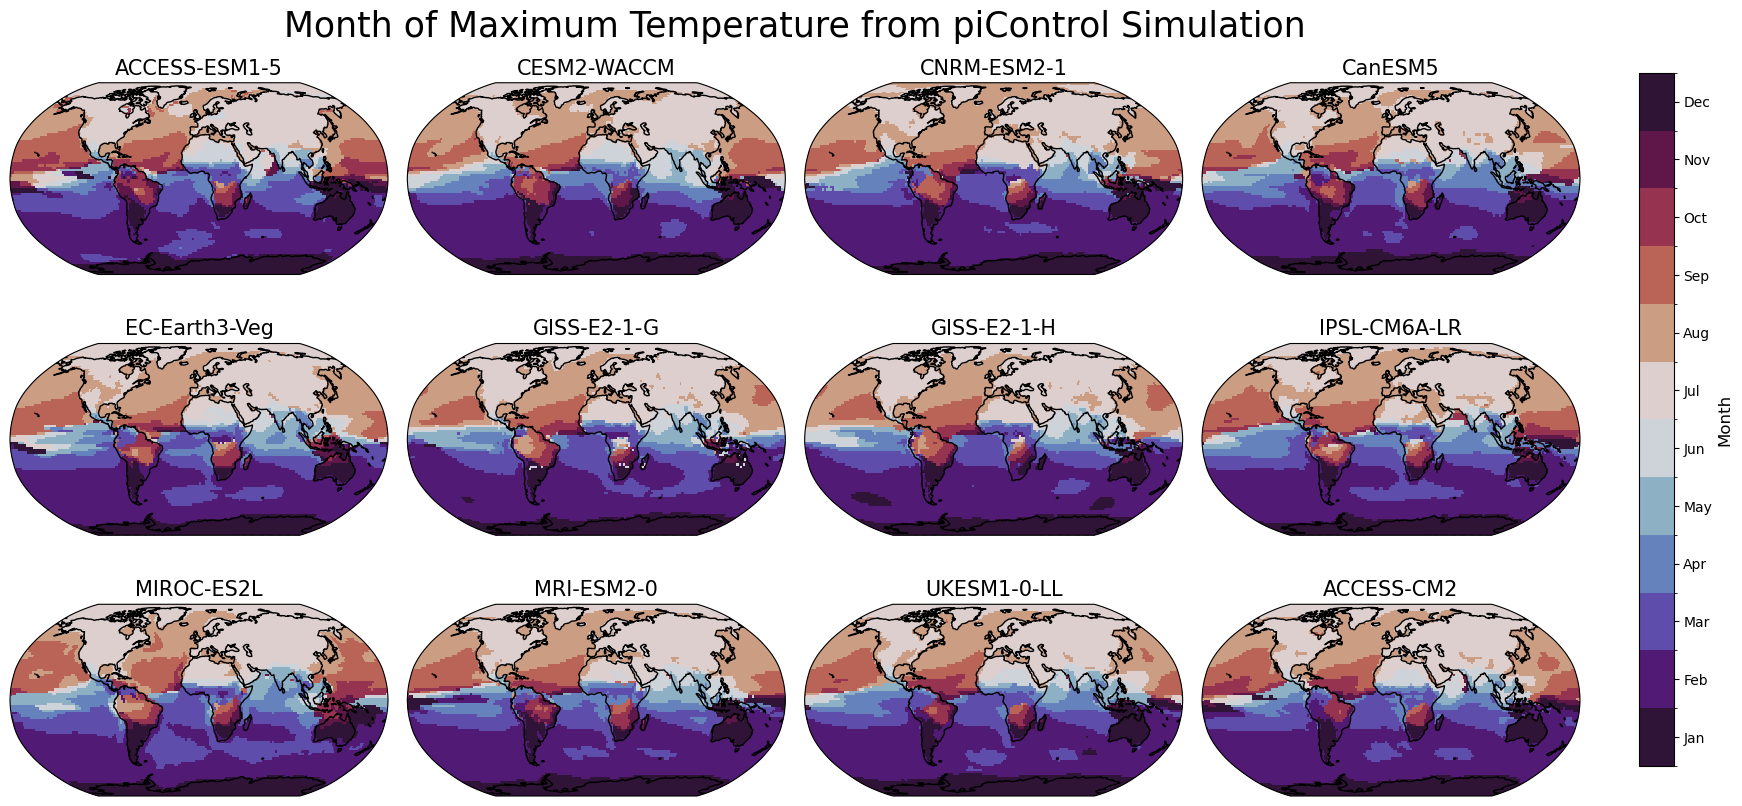

In [50]:
plot_hottest_coldest_month(
    extreme_months,
    'max',
    "Month of Maximum Temperature from piControl Simulation"
)

#### Step 2 & Step 3: Calculate the monthly means and standard deviations for each grid cell's month of maximum temperature ####

In [15]:
ext_results = defaultdict(dict)
for model, member_dt in extreme_months.items():
    for member, dt in member_dt.items():
        ext_results[model][member] = {'extreme_months': dt.ds}
ext_results = dict(ext_results)

In [16]:
for model, member_dt in regridded_pi_dt.items():
    for member, dt in member_dt.items():
        ds = dt.ds.tas
        for extrema in ['max','min']:
            months = extreme_months[model][member].ds.month.sel(extrema=extrema)
            ext_results[model][member][f"{extrema}_month_mean"] =  ext_freq.extreme_month_stat(ds,months,'mean')
            ext_results[model][member][f"{extrema}_month_std_dev"] = ext_freq.extreme_month_stat(ds,months,'std')

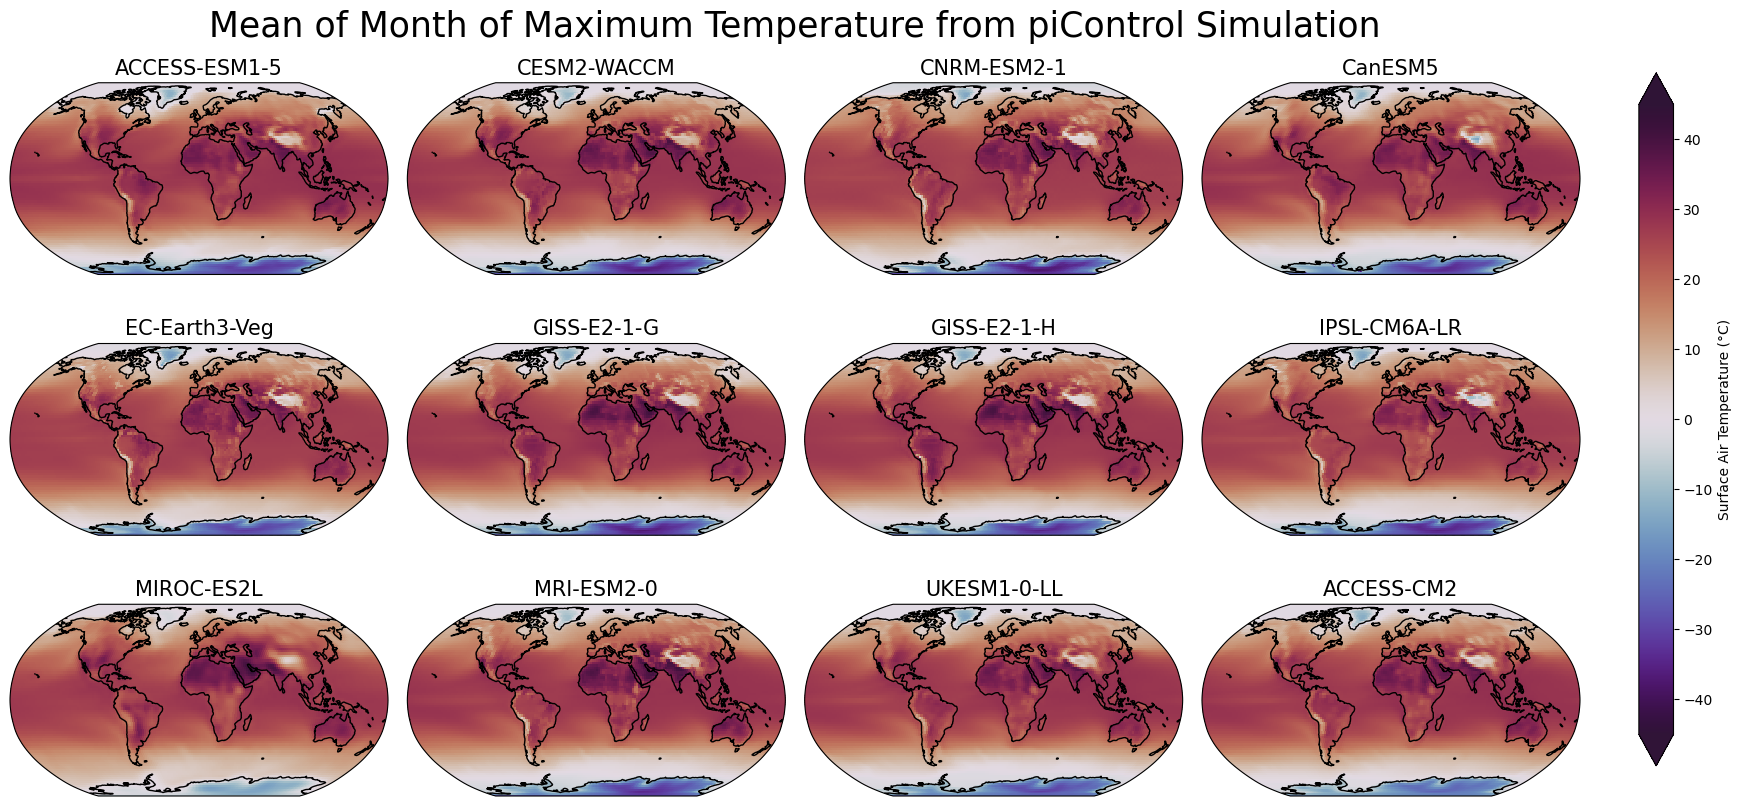

In [106]:
plot_pi_stats(
    ext_results,
    'max_month_mean',
    cmap='twilight_shifted',
    vmin=-45,
    vmax=45,
    cbar_label="Surface Air Temperature (°C)",
    title="Mean of Month of Maximum Temperature from piControl Simulation"
)

#### Step 4: Calculate extreme temperature thresholds based on standard deviations from mean hottest/coldest month temperatures ####

In [17]:
for model, member_dict in ext_results.items():
    for member, ds_dict in member_dict.items():
        ext_results[model][member]['heat_thresholds'] = ext_freq.heat_extreme_thresholds(
            ds_dict['max_month_mean'],
            ds_dict['max_month_std_dev']
        )
        ext_results[model][member]['cold_thresholds'] = ext_freq.cold_extreme_thresholds(
            ds_dict['min_month_mean'],
            ds_dict['min_month_std_dev']
        )

## Calculate Extreme Temperature Extreme Frequency

### Select hottest and coldest months for ScenariMIP experiments ###

#### & Rename 'max' 'min' coordinates to calculate 'cold' and 'heat' extremes ####

In [18]:
extreme_months_dict = defaultdict(dict)
for model, member_dict in ext_results.items():
    for member, ds_dict in member_dict.items():
        da = ds_dict['extreme_months']
        new_da = da.assign_coords(
            extrema=xr.where(
                da.extrema == 'max', 'heat',
                xr.where(da.extrema == 'min', 'cold', da.extrema)
            )
        )
        extreme_months_dict[model][member] = new_da
extreme_months_dict = dict(extreme_months_dict)

### Load GWL years

In [19]:
path = proc_dir / "ScenarioMIP" / "gwl_years" / "gwl_years.nc"
gwl_years = xr.open_dataset(path)
gwl_years

<xarray.Dataset> Size: 57kB
Dimensions:        (model: 13, expt: 2, member: 85)
Coordinates:
  * model          (model) <U13 676B 'ACCESS-CM2' ... 'UKESM1-0-LL'
  * expt           (expt) <U11 88B 'ssp126' 'ssp534-over'
  * member         (member) <U9 3kB 'r10i1p1f1' 'r10i1p1f2' ... 'r9i1p1f2'
Data variables:
    gwl            (model, expt, member) float64 18kB ...
    pre_gwl_year   (model, expt, member) float64 18kB ...
    post_gwl_year  (model, expt, member) float64 18kB ...

### Index data by GWL period ###

In [20]:
gwl_periods = defaultdict(lambda: defaultdict(dict))
for model, expt_dt in regridded_dt.items():
    if model not in extreme_months_dict.keys():
        print(f"Skipping {model}")
        continue
        
    for expt, member_dt in expt_dt.items():
        for member, dt in member_dt.items():
            if member not in extreme_months_dict[model].keys():
                print(f"Skipping {model} {member}")
                continue
            ds = dt.ds
            ext_months = extreme_months_dict[model][member]
            ext_month_tas = ext_freq.select_extreme_month(ds,ext_months)
            gwl_years_ds = gwl_years.sel(model=model,expt=expt,member=member)
            gwl_period = utils_scenariomip.extract_gwl_period_scenariomip(
                ext_month_tas, 
                gwl_years_ds, 
                31, 
                time_dim='year'
            )
            gwl_periods[model][expt][member] = gwl_period

gwl_periods = utils.defaultdict_to_dict(gwl_periods)

Skipping GISS-E2-1-H r1i1p1f2
Skipping GISS-E2-1-H r2i1p1f2
Skipping GISS-E2-1-H r3i1p1f2
Skipping GISS-E2-1-H r4i1p1f2
Skipping GISS-E2-1-H r5i1p1f2
Skipping GISS-E2-1-H r1i1p1f2
Skipping GISS-E2-2-G


In [21]:
gwl_periods

{'ACCESS-ESM1-5': {'ssp534-over': {'r10i1p1f2': <xarray.Dataset> Size: 16MB
   Dimensions:  (period: 2, extrema: 2, year: 62, lat: 90, lon: 180)
   Coordinates:
     * period   (period) <U4 32B 'pre' 'post'
     * extrema  (extrema) <U4 32B 'heat' 'cold'
     * year     (year) int64 496B 2021 2022 2023 2024 2025 ... 2197 2198 2199 2200
     * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
     * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
       gwl      float64 8B 1.84
   Data variables:
       tas      (period, extrema, year, lat, lon) float32 16MB dask.array<chunksize=(1, 1, 15, 90, 180), meta=np.ndarray>
   Attributes:
       regrid_method:  bilinear,
   'r11i1p1f2': <xarray.Dataset> Size: 16MB
   Dimensions:  (period: 2, extrema: 2, year: 62, lat: 90, lon: 180)
   Coordinates:
     * period   (period) <U4 32B 'pre' 'post'
     * extrema  (extrema) <U4 32B 'heat' 'cold'
     * year     (year) int64 496B 2022 2023 2024 20

## Calculate frequency of extreme threshold exceedance ##

In [22]:
exceedances = defaultdict(dict)

for model, expt_dt in gwl_periods.items():
    for expt, member_dt in expt_dt.items():
        # collect per-member exceedances for each ext_type
        member_exceedances = {'heat': [], 'cold': []}

        for member, dt in member_dt.items():
            gwl_period = dt.tas
            for ext_type in ['heat', 'cold']:
                thresholds = ext_results[model][member][f'{ext_type}_thresholds']
                print(f"Calculating {ext_type} exceedances for {model} {expt} {member}")
                exc = ext_freq.calculate_exceedances(
                    gwl_period,
                    thresholds,
                    ext_type=ext_type,
                )
                member_exceedances[ext_type].append(exc.assign_coords(member=member))

        # average across members for each ext_type, keep both in the result
        expt_result = {}
        for ext_type in ['heat', 'cold']:
            expt_result[f'{ext_type}_exceedances'] = xr.concat(
                member_exceedances[ext_type], dim='member'
            ).mean(dim='member').drop_vars('gwl', errors='ignore')

        exceedances[model][expt] = expt_result

exceedances = dict(exceedances)
        
                
                

Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r10i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r10i1p1f2
Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r11i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r11i1p1f2
Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r12i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r12i1p1f2
Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r13i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r13i1p1f2
Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r14i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r14i1p1f2
Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r15i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r15i1p1f2
Calculating heat exceedances for ACCESS-ESM1-5 ssp534-over r16i1p1f2
Calculating cold exceedances for ACCESS-ESM1-5 ssp534-over r16i1p1f2
Calculating heat exceedances for A

## Calculate multi-model median

In [25]:
# want median across models for both expts
model_keys = [m for m in exceedances.keys() if m != 'median']

exceedances['median'] = {
    expt: {
        ext_type: xr.concat(
            [
                exceedances[model][expt][ext_type]
                for model in model_keys
                if expt in exceedances[model]
            ],
            dim='model',
            compat='override',
            coords='minimal'
        ).median(dim='model')
        for ext_type in ['heat_exceedances', 'cold_exceedances']
    }
    for expt in ['ssp534-over', 'ssp126']
}


## Save

In [26]:
save_dir = proc_dir / "ScenarioMIP" / "extremes"
for model, expt_dict in exceedances.items():
    for expt, ds_dict in expt_dict.items():
        for var, ds in ds_dict.items():
            
            var_dir = save_dir / var
            model_dir = var_dir / model
            expt_dir = model_dir / expt

            os.makedirs(expt_dir,exist_ok=True)
            path = expt_dir / f"{model}_{expt}_{var}.nc"
            if path.exists():
                print(f"Skipping (already exists): {path}")
                continue
            print(f"Saving to {path}")
            ds.to_netcdf(path)

Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/heat_exceedances/ACCESS-ESM1-5/ssp534-over/ACCESS-ESM1-5_ssp534-over_heat_exceedances.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/ACCESS-ESM1-5/ssp534-over/ACCESS-ESM1-5_ssp534-over_cold_exceedances.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/heat_exceedances/ACCESS-ESM1-5/ssp126/ACCESS-ESM1-5_ssp126_heat_exceedances.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/cold_exceedances/ACCESS-ESM1-5/ssp126/ACCESS-ESM1-5_ssp126_cold_exceedances.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/heat_exceedances/CESM2-WACCM/ssp534-over/CESM2-WACCM_ssp534-over_heat_exceedances.nc
Skipping (already exists): /home/563/sc1326/repos/cdrmip_extremes/dat

## Save max/min month temps at equiv. GWLs

In [ ]:
save_dir = proc_dir / "ScenarioMIP" / "extremes" / 'extreme_month_tas'
for model, expt_dict in gwl_periods.items():

    for expt, member_dict in expt_dict.items():
        # collect per-member exceedances for each ext_type
        member_vals = []
        for member, ds in member_dict.items():
            member_vals.append(ds.assign_coords(member=member))
        
        ens_median = xr.concat(
            member_vals,
            dim='member'
        ).median(dim='member')

        # save
        expt_dir = save_dir / model / expt
        os.makedirs(expt_dir,exist_ok=True)
        path = expt_dir / f"{model}_{expt}_extreme_month_tas.nc"
        if path.exists():
            print(f"Skipping (already exists): {path}")
            continue
        print(f"Saving to {path}")
        ens_median.to_netcdf(path)

Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/extreme_month_tas/ACCESS-ESM1-5/ssp534-over/ACCESS-ESM1-5_ssp534-over_extreme_month_tas.nc


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_c

Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/extreme_month_tas/ACCESS-ESM1-5/ssp126/ACCESS-ESM1-5_ssp126_extreme_month_tas.nc


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_c

Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/extreme_month_tas/CESM2-WACCM/ssp534-over/CESM2-WACCM_ssp534-over_extreme_month_tas.nc


...

Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/extreme_month_tas/GISS-E2-1-G/ssp534-over/GISS-E2-1-G_ssp534-over_extreme_month_tas.nc


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)


Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/extreme_month_tas/GISS-E2-1-H/ssp534-over/GISS-E2-1-H_ssp534-over_extreme_month_tas.nc


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.02/lib/python3.11/site-packages/dask/_task_spec.py:767: RuntimeWarning: All-NaN slice encountered
  return self.func(*new_argspec, **kwargs)
/g/data/xp65/public/apps/med_c

Saving to /home/563/sc1326/repos/cdrmip_extremes/data/processed/ScenarioMIP/extremes/extreme_month_tas/IPSL-CM6A-LR/ssp534-over/IPSL-CM6A-LR_ssp534-over_extreme_month_tas.nc


## Save other extreme data

In [38]:
ext_results

{'ACCESS-ESM1-5': {'r10i1p1f2': {'extreme_months': <xarray.DatasetView> Size: 261kB
   Dimensions:  (extrema: 2, lat: 90, lon: 180)
   Coordinates:
     * extrema  (extrema) <U3 24B 'max' 'min'
     * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
     * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
   Data variables:
       month    (extrema, lat, lon) float64 259kB dask.array<chunksize=(1, 90, 180), meta=np.ndarray>
   Attributes:
       regrid_method:  bilinear,
   'max_month_mean': <xarray.DataArray 'tas' (lat: 90, lon: 180)> Size: 65kB
   dask.array<mean_agg-aggregate, shape=(90, 180), dtype=float32, chunksize=(90, 180), chunktype=numpy.ndarray>
   Coordinates:
     * lat      (lat) float64 720B -89.5 -87.49 -85.48 -83.47 ... 85.48 87.49 89.5
     * lon      (lon) float64 1kB -179.5 -177.5 -175.5 -173.5 ... 175.5 177.5 179.5
       extrema  <U3 12B 'max',
   'max_month_std_dev': <xarray.DataArray 'tas' (lat: 90, lon: 180)